In [1]:
import os, time
os.environ["PYSPARK_SUBMIT_ARGS"] = "--driver-memory 4g pyspark-shell"

import pandas as pd
import numpy as np
from pyspark.sql import SparkSession, functions as F

spark = SparkSession.builder.appName("phase4-full-scale").getOrCreate()

tx = spark.read.parquet("/home/jovyan/work/data/processed/train_features")
total_rows = tx.count()
print(f"features table: {total_rows:,} rows x {len(tx.columns)} cols")

features table: 590,540 rows x 298 cols


In [ ]:
import sys, pyspark
print(sys.executable)        # expect /opt/conda/bin/python
print(pyspark.__version__)   # expect 3.5.0

/opt/conda/bin/python
3.5.0


In [2]:
max_day = tx.agg(F.max("day")).collect()[0][0]
cutoff  = max_day - 17

train = tx.filter(F.col("day") <= cutoff)
test  = tx.filter(F.col("day") >  cutoff)

for name, df in [("train", train), ("test", test)]:
    n  = df.count()
    fr = df.filter(F.col("isFraud") == 1).count() / n * 100
    print(f"{name}: {n:,} rows | fraud rate {fr:.2f}%")
print(f"split: train days <= {cutoff}, test days {cutoff+1} to {max_day}")

train: 543,948 rows | fraud rate 3.47%
test: 46,592 rows | fraud rate 3.88%
split: train days <= 165, test days 166 to 182


In [3]:
num_cols = [c for c, t in train.dtypes
            if t in ("int", "bigint", "double", "float")
            and c not in ("isFraud", "TransactionID")]

t0 = time.time()
meds = train.approxQuantile(num_cols, [0.5], 0.001)

med_map = {}
for c, m in zip(num_cols, meds):
    if not m or m[0] is None:
        continue
    t = next(t for cc, t in train.dtypes if cc == c)
    med_map[c] = int(round(m[0])) if t in ("int", "bigint") else float(m[0])

train = train.na.fill(med_map)
test  = test.na.fill(med_map)
print(f"{len(med_map)} numeric cols median-imputed in {time.time()-t0:.1f}s")

282 numeric cols median-imputed in 84.1s


In [4]:
from pyspark.ml.feature import StringIndexer

str_cols = [c for c, t in train.dtypes if t == "string"]
idx_cols = [c + "_idx" for c in str_cols]

train = train.drop(*idx_cols)
test  = test.drop(*idx_cols)

train = train.na.fill("__NA__", subset=str_cols)
test  = test.na.fill("__NA__", subset=str_cols)

t0 = time.time()
for c in str_cols:
    indexer = StringIndexer(inputCol=c, outputCol=c + "_idx", handleInvalid="keep")
    model   = indexer.fit(train)
    train   = model.transform(train)
    test    = model.transform(test)
    train   = train.drop(c)
    test    = test.drop(c)

print(f"indexed {len(str_cols)} string cols in {time.time()-t0:.1f}s")

indexed 14 string cols in 33.9s


In [5]:
from pyspark.ml.feature import VectorAssembler

spark.catalog.clearCache()      # kill zombie cache blocks from any earlier re-run
t0 = time.time()
n_train = train.cache().count()
fraud_n = train.filter(F.col("isFraud") == 1).count()
legit_n = n_train - fraud_n
ratio   = legit_n / fraud_n
w_fraud = float(np.sqrt(ratio))          # the Step-9b winner: ~5x, not 28x
print(f"train: {n_train:,} rows | fraud {fraud_n:,} / legit {legit_n:,}")
print(f"weight scheme: sqrt | fraud rows weigh {w_fraud:.2f}x")

train = train.withColumn("weight", F.when(F.col("isFraud") == 1, w_fraud).otherwise(1.0))
test  = test.withColumn("weight", F.when(F.col("isFraud") == 1, w_fraud).otherwise(1.0))

idx_cols = [c for c in train.columns if c.endswith("_idx")]
for c in idx_cols:                        # strip nominal metadata (maxBins armor)
    train = train.withColumn(c, F.col(c) * 1.0)
    test  = test.withColumn(c, F.col(c) * 1.0)

assembler_inputs = [c for c, t in train.dtypes
                    if t in ("int", "bigint", "double", "float")
                    and c not in ("isFraud", "TransactionID", "weight", "TransactionDT")]

assembler = VectorAssembler(inputCols=assembler_inputs, outputCol="features", handleInvalid="keep")
train_vec = assembler.transform(train).select("TransactionID", "day", "isFraud", "features", "weight").cache()
test_vec  = assembler.transform(test).select("TransactionID", "day", "isFraud", "features", "weight").cache()
print(f"train_vec: {train_vec.count():,} rows | test_vec: {test_vec.count():,} rows")
print(f"{len(assembler_inputs)} features | assembled in {time.time()-t0:.1f}s")

train: 543,948 rows | fraud 18,854 / legit 525,094
weight scheme: sqrt | fraud rows weigh 5.28x
train_vec: 543,948 rows | test_vec: 46,592 rows
295 features | assembled in 116.6s


In [6]:
from pyspark.ml.evaluation import BinaryClassificationEvaluator

def score(pred):
    ev = BinaryClassificationEvaluator(labelCol="isFraud", rawPredictionCol="probability")
    tp = pred.filter("isFraud=1 and prediction=1").count()
    fp = pred.filter("isFraud=0 and prediction=1").count()
    fn = pred.filter("isFraud=1 and prediction=0").count()
    tn = pred.filter("isFraud=0 and prediction=0").count()
    prec = tp/(tp+fp) if tp+fp else 0.0
    rec  = tp/(tp+fn) if tp+fn else 0.0
    f1   = 2*prec*rec/(prec+rec) if prec+rec else 0.0
    return dict(prAUC=round(ev.setMetricName("areaUnderPR").evaluate(pred), 4),
                rocAUC=round(ev.setMetricName("areaUnderROC").evaluate(pred), 4),
                precision=round(prec, 3), recall=round(rec, 3),
                f1=round(f1, 3), accuracy=round((tp+tn)/(tp+fp+fn+tn), 4))

def show_scores(name, sco, elapsed):
    print(f"=== {name} | fit+score {elapsed:.1f}s " + "=" * max(0, 28 - len(name)))
    print(f"{'metric':<12}{'train':>10}{'test':>10}")
    for k in ["prAUC", "rocAUC", "precision", "recall", "f1", "accuracy"]:
        print(f"{k:<12}{sco['train'][k]:>10}{sco['test'][k]:>10}")

print("scorer ready")

scorer ready


In [7]:
from pyspark.ml.classification import LogisticRegression

t0 = time.time()
lr = LogisticRegression(labelCol="isFraud", featuresCol="features",
                        weightCol="weight", maxIter=20, regParam=0.01)
lr_m   = lr.fit(train_vec)
lr_sco = {"train": score(lr_m.transform(train_vec)), "test": score(lr_m.transform(test_vec))}
show_scores("Logistic Regression", lr_sco, time.time() - t0)

=== Logistic Regression | fit+score 53.3s =========
metric           train      test
prAUC           0.3903    0.1768
rocAUC           0.847    0.8357
precision        0.488     0.277
recall           0.346       0.4
f1               0.405     0.327
accuracy        0.9648    0.9362


In [8]:
from pyspark.ml.classification import RandomForestClassifier

t0 = time.time()
rf = RandomForestClassifier(labelCol="isFraud", featuresCol="features",
                            weightCol="weight", numTrees=60, maxDepth=8, seed=42)
rf_m   = rf.fit(train_vec)
rf_sco = {"train": score(rf_m.transform(train_vec)), "test": score(rf_m.transform(test_vec))}
show_scores("Random Forest", rf_sco, time.time() - t0)

=== Random Forest | fit+score 107.0s ===============
metric           train      test
prAUC            0.499    0.4863
rocAUC          0.8697    0.8642
precision        0.732     0.742
recall           0.361      0.35
f1               0.484     0.476
accuracy        0.9733    0.9701


In [16]:
from pyspark.ml.classification import GBTClassifier

t0 = time.time()
gbt_d5 = GBTClassifier(labelCol="isFraud", featuresCol="features",
                       weightCol="weight", maxIter=50, maxDepth=5, stepSize=0.1, seed=42)
gbt_d5_m   = gbt_d5.fit(train_vec)
d5_sco = {"train": score(gbt_d5_m.transform(train_vec)), "test": score(gbt_d5_m.transform(test_vec))}
show_scores("GBT d5 i50 s0.1", d5_sco, time.time() - t0)

=== GBT d5 i50 s0.1 | fit+score 191.0s =============
metric           train      test
prAUC           0.5637     0.486
rocAUC          0.9058    0.8874
precision        0.554     0.525
recall           0.533     0.469
f1               0.543     0.495
accuracy        0.9689    0.9629


In [17]:
from pyspark.ml.classification import GBTClassifier

t0 = time.time()
gbt_d3 = GBTClassifier(labelCol="isFraud", featuresCol="features",
                       weightCol="weight", maxIter=50, maxDepth=3, stepSize=0.1, seed=42)
gbt_d3_m   = gbt_d3.fit(train_vec)
d3_sco = {"train": score(gbt_d3_m.transform(train_vec)), "test": score(gbt_d3_m.transform(test_vec))}
show_scores("GBT d3 i50 s0.1", d3_sco, time.time() - t0)

=== GBT d3 i50 s0.1 | fit+score 139.1s =============
metric           train      test
prAUC           0.4624    0.4531
rocAUC           0.882    0.8722
precision        0.514     0.516
recall           0.429     0.435
f1               0.467     0.472
accuracy        0.9661    0.9622


In [18]:
rows = []
for name, sco in [("LR", lr_sco), ("RF", rf_sco), ("GBT-d5", d5_sco), ("GBT-d3", d3_sco)]:
    for split in ("train", "test"):
        row = {"model": name, "split": split}
        row.update(sco[split])
        rows.append(row)

comp = pd.DataFrame(rows)
print(comp.to_string(index=False))

best = comp[comp["split"] == "test"].sort_values("prAUC", ascending=False).iloc[0]
print(f"\nwinner on test prAUC: {best['model']} at {best['prAUC']:.4f}")

 model split  prAUC  rocAUC  precision  recall    f1  accuracy
    LR train 0.3903  0.8470      0.488   0.346 0.405    0.9648
    LR  test 0.1768  0.8357      0.277   0.400 0.327    0.9362
    RF train 0.4990  0.8697      0.732   0.361 0.484    0.9733
    RF  test 0.4863  0.8642      0.742   0.350 0.476    0.9701
GBT-d5 train 0.5637  0.9058      0.554   0.533 0.543    0.9689
GBT-d5  test 0.4860  0.8874      0.525   0.469 0.495    0.9629
GBT-d3 train 0.4624  0.8820      0.514   0.429 0.467    0.9661
GBT-d3  test 0.4531  0.8722      0.516   0.435 0.472    0.9622

winner on test prAUC: RF at 0.4863


In [19]:
from pyspark.ml.functions import vector_to_array

winner_m, winner_name = (gbt_d5_m, "GBT-d5") if d5_sco["test"]["prAUC"] >= d3_sco["test"]["prAUC"] else (gbt_d3_m, "GBT-d3")
print(f"threshold work on winner: {winner_name}")

scored = winner_m.transform(test_vec)
pdf = (scored.select("isFraud",
                     vector_to_array("probability")[1].alias("p_fraud"))
             .toPandas())               # 46,592 rows to the driver: tiny, safe

thresholds = np.arange(0.05, 1.0, 0.05)
srows = []
y = pdf["isFraud"].astype(int)
for t in thresholds:
    pred = (pdf["p_fraud"] >= t).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum())
    fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum())
    prec = tp/(tp+fp) if tp+fp else 0.0
    rec  = tp/(tp+fn) if tp+fn else 0.0
    f1   = 2*prec*rec/(prec+rec) if prec+rec else 0.0
    srows.append({"threshold": round(float(t), 2), "precision": round(prec, 3),
                  "recall": round(rec, 3), "f1": round(f1, 3), "alerted": int(pred.sum())})

sweep = pd.DataFrame(srows)
print(sweep.to_string(index=False))
best_t = sweep.loc[sweep["f1"].idxmax()]
print(f"\nbest F1 operating point: threshold {best_t['threshold']} -> "
      f"precision {best_t['precision']}, recall {best_t['recall']}, F1 {best_t['f1']}, "
      f"{best_t['alerted']:,} txns flagged of {len(pdf):,}")

threshold work on winner: GBT-d5
 threshold  precision  recall    f1  alerted
      0.05      0.054   0.972 0.103    32293
      0.10      0.114   0.851 0.201    13487
      0.15      0.153   0.789 0.256     9320
      0.20      0.212   0.724 0.328     6183
      0.25      0.270   0.655 0.383     4381
      0.30      0.322   0.617 0.423     3473
      0.35      0.374   0.570 0.451     2760
      0.40      0.421   0.538 0.473     2311
      0.45      0.476   0.502 0.489     1909
      0.50      0.525   0.469 0.495     1618
      0.55      0.563   0.440 0.494     1415
      0.60      0.595   0.411 0.486     1251
      0.65      0.626   0.379 0.472     1096
      0.70      0.682   0.358 0.470      950
      0.75      0.739   0.330 0.456      808
      0.80      0.791   0.299 0.433      683
      0.85      0.830   0.273 0.411      595
      0.90      0.854   0.217 0.346      459
      0.95      0.845   0.097 0.174      207

best F1 operating point: threshold 0.5 -> precision 0.525, recall 

saved: reports/figures/pr_roc_curves.png


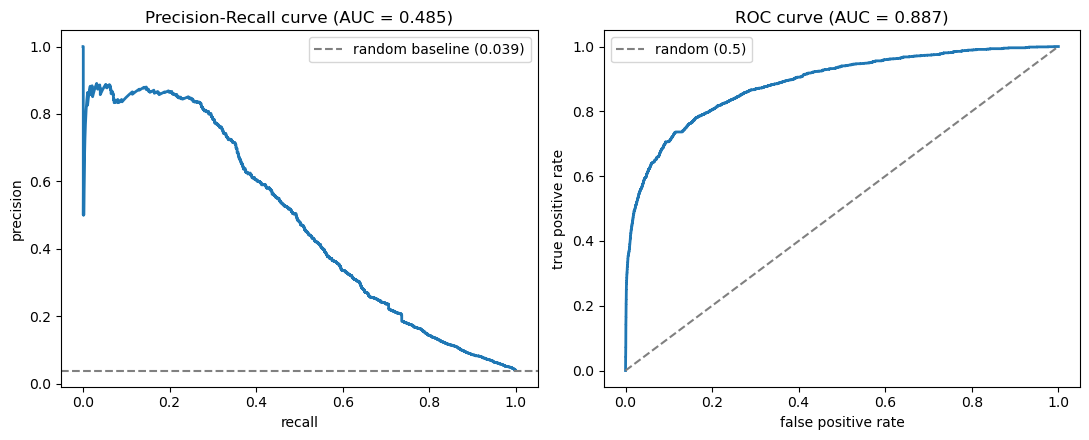

In [21]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, roc_curve, auc

y = pdf["isFraud"].astype(int)
p = pdf["p_fraud"]
pr, rc, _ = precision_recall_curve(y, p)
fpr, tpr, _ = roc_curve(y, p)
pr_auc = auc(rc, pr)
roc_auc = auc(fpr, tpr)
base_rate = y.mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(rc, pr, lw=2)
axes[0].axhline(base_rate, ls="--", c="gray", label=f"random baseline ({base_rate:.3f})")
axes[0].set_xlabel("recall"); axes[0].set_ylabel("precision")
axes[0].set_title(f"Precision-Recall curve (AUC = {pr_auc:.3f})")
axes[0].legend()
axes[1].plot(fpr, tpr, lw=2)
axes[1].plot([0, 1], [0, 1], ls="--", c="gray", label="random (0.5)")
axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
axes[1].set_title(f"ROC curve (AUC = {roc_auc:.3f})")
axes[1].legend()
fig.tight_layout()
fig.savefig("/home/jovyan/work/reports/figures/pr_roc_curves.png", dpi=150, bbox_inches="tight")
print("saved: reports/figures/pr_roc_curves.png")

In [23]:
import os, shutil
model_dir = "/home/jovyan/work/models/gbt_winner"
if os.path.isdir(model_dir):
    shutil.rmtree(model_dir)
winner_m.write().save(model_dir)

feature_importance = pd.DataFrame({"feature": assembler_inputs,
                                   "importance": winner_m.featureImportances.toArray()})
top = feature_importance.sort_values("importance", ascending=False).head(10).reset_index(drop=True)
top["share_pct"] = (top["importance"] * 100).round(2)

te = winner_sco_test = d5_sco["test"] if winner_name == "GBT-d5" else d3_sco["test"]
print("PHASE 4 FINAL CARD")
print(f"  model           : {winner_name} (sqrt weights ~{w_fraud:.2f}x)")
print(f"  test prAUC      : {te['prAUC']} | test rocAUC: {te['rocAUC']}")
print(f"  operating point : threshold {best_t['threshold']} -> precision {best_t['precision']}, recall {best_t['recall']}")
print(f"  model saved to  : models/gbt_winner")
print("\ntop-10 features of the final model:")
print(top[["feature", "importance", "share_pct"]].to_string(index=False))

PHASE 4 FINAL CARD
  model           : GBT-d5 (sqrt weights ~5.28x)
  test prAUC      : 0.486 | test rocAUC: 0.8874
  operating point : threshold 0.5 -> precision 0.525, recall 0.469
  model saved to  : models/gbt_winner

top-10 features of the final model:
       feature  importance  share_pct
          V258    0.055062       5.51
           C13    0.045947       4.59
            C1    0.044179       4.42
TransactionAmt    0.040700       4.07
 card1_amt_avg    0.040200       4.02
           C14    0.039111       3.91
           C11    0.034832       3.48
           day    0.029701       2.97
     card6_idx    0.026344       2.63
         card3    0.025791       2.58


In [24]:
from pyspark.ml.functions import vector_to_array

scored_rf = rf_m.transform(test_vec)
pdf_rf = (scored_rf.select("isFraud",
                           vector_to_array("probability")[1].alias("p_fraud"))
                 .toPandas())

thresholds = np.arange(0.05, 1.0, 0.05)
srows = []
y = pdf_rf["isFraud"].astype(int)
for t in thresholds:
    pred = (pdf_rf["p_fraud"] >= t).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum())
    fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum())
    prec = tp/(tp+fp) if tp+fp else 0.0
    rec  = tp/(tp+fn) if tp+fn else 0.0
    f1   = 2*prec*rec/(prec+rec) if prec+rec else 0.0
    srows.append({"threshold": round(float(t), 2), "precision": round(prec, 3),
                  "recall": round(rec, 3), "f1": round(f1, 3), "alerted": int(pred.sum())})

sweep_rf = pd.DataFrame(srows)
print(sweep_rf.to_string(index=False))

best_rf = sweep_rf.loc[sweep_rf["f1"].idxmax()]
print(f"\nbest F1 operating point: threshold {best_rf['threshold']} -> "
      f"precision {best_rf['precision']}, recall {best_rf['recall']}, F1 {best_rf['f1']}, "
      f"{int(best_rf['alerted']):,} txns flagged of {len(pdf_rf):,}")

print("\n=== OPERATING POINT CARD (both champions, test set) ===")
card = pd.DataFrame([
    {"model": "GBT-d5", "threshold": float(best_t["threshold"]),
     "precision": best_t["precision"], "recall": best_t["recall"],
     "f1": best_t["f1"], "alerted": int(best_t["alerted"])},
    {"model": "RF", "threshold": float(best_rf["threshold"]),
     "precision": best_rf["precision"], "recall": best_rf["recall"],
     "f1": best_rf["f1"], "alerted": int(best_rf["alerted"])},
])
print(card.to_string(index=False))

 threshold  precision  recall    f1  alerted
      0.05      0.051   0.965 0.097    34317
      0.10      0.085   0.876 0.155    18700
      0.15      0.128   0.794 0.220    11240
      0.20      0.187   0.663 0.292     6400
      0.25      0.241   0.574 0.339     4317
      0.30      0.405   0.514 0.453     2294
      0.35      0.498   0.465 0.481     1690
      0.40      0.596   0.430 0.499     1303
      0.45      0.682   0.384 0.492     1019
      0.50      0.742   0.350 0.476      854
      0.55      0.779   0.333 0.467      774
      0.60      0.801   0.313 0.451      708
      0.65      0.843   0.296 0.438      635
      0.70      0.876   0.269 0.411      555
      0.75      0.894   0.233 0.370      472
      0.80      0.909   0.200 0.327      397
      0.85      0.918   0.162 0.275      319
      0.90      0.948   0.091 0.165      173
      0.95      0.985   0.036 0.070       67

best F1 operating point: threshold 0.4 -> precision 0.596, recall 0.43, F1 0.499, 1,303 txns flagge